**IMPORTS AND LOAD**

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, recall_score,
                             precision_score, confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, precision_recall_curve)

os.makedirs("../reports/figures", exist_ok=True)

df = pd.read_csv("../data/features.csv")

# these were saved as text labels but CSV turns pure numbers back into integers
for c in ["admission_type_id", "admission_source_id", "discharge_disposition_id"]:
    df[c] = df[c].astype(str)

print(df.shape)

(69987, 29)


**SPLIT AND PREPROCESS**

In [5]:
y = df["target"]
X = df.drop(columns=["target"])

cat_cols = X.select_dtypes(include="object").columns.tolist()
num_cols = [c for c in X.columns if c not in cat_cols]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Positive rate train/test:", y_train.mean().round(3), y_test.mean().round(3))

C:\Users\Badaplin\AppData\Local\Temp\ipykernel_29692\692152904.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include="object").columns.tolist()


Train: (55989, 28) | Test: (13998, 28)
Positive rate train/test: 0.09 0.09


**PREPROCESSING AND MODELS**

In [6]:
pre = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])

models = {
    "logreg": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "rf": RandomForestClassifier(
        n_estimators=300, min_samples_leaf=20,
        class_weight="balanced_subsample", n_jobs=-1, random_state=42
    ),
}
pipes = {name: Pipeline([("pre", pre), ("clf", clf)]) for name, clf in models.items()}

**CROSS-VALIDATION ON THE TRAINING SET**

In [7]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for name, pipe in pipes.items():
    scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=1)
    print(f"{name}: CV AUC = {scores.mean():.3f} (+/- {scores.std():.3f})")

logreg: CV AUC = 0.641 (+/- 0.003)
rf: CV AUC = 0.652 (+/- 0.006)


**FIT AND SCORE ON THE TEST SET**

In [8]:
rows = []
probas = {}
for name, pipe in pipes.items():
    pipe.fit(X_train, y_train)
    p = pipe.predict_proba(X_test)[:, 1]
    probas[name] = p
    rows.append({
        "model": name,
        "ROC-AUC": roc_auc_score(y_test, p),
        "PR-AUC": average_precision_score(y_test, p),
        "Recall@0.5": recall_score(y_test, p >= 0.5),
        "Precision@0.5": precision_score(y_test, p >= 0.5),
    })

results = pd.DataFrame(rows).round(3)
results.to_csv("../reports/model_results.csv", index=False)
results

,model,ROC-AUC,PR-AUC,Recall@0.5,Precision@0.5
0,logreg,0.646,0.164,0.543,0.137
1,rf,0.655,0.177,0.364,0.183


**BEST MODEL**

In [9]:
best_name = "rf"  

**ROC and precision-recall curves**

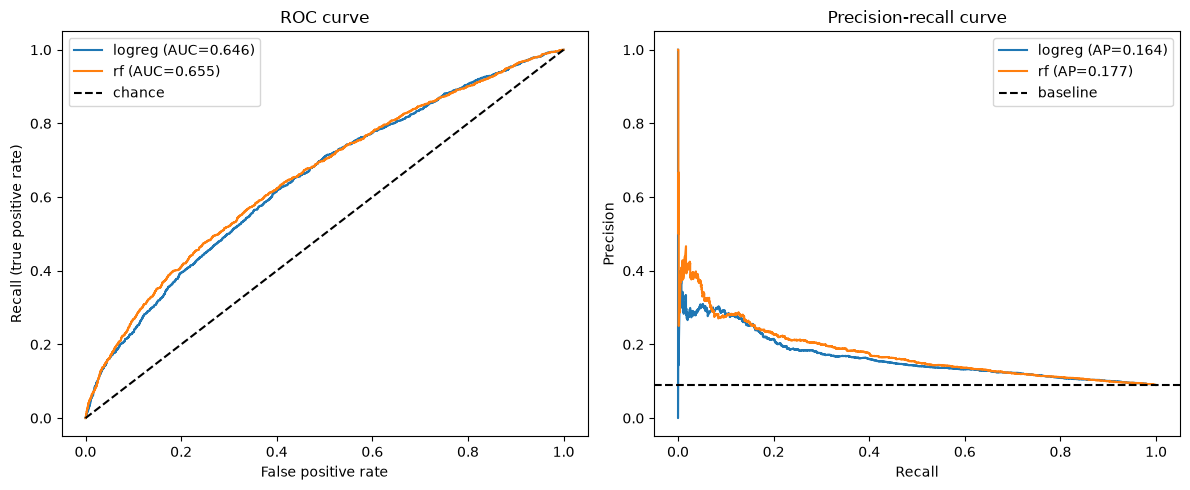

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

for name, p in probas.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    ax[0].plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, p):.3f})")
ax[0].plot([0, 1], [0, 1], "k--", label="chance")
ax[0].set_xlabel("False positive rate"); ax[0].set_ylabel("Recall (true positive rate)")
ax[0].set_title("ROC curve"); ax[0].legend()

for name, p in probas.items():
    prec, rec, _ = precision_recall_curve(y_test, p)
    ax[1].plot(rec, prec, label=f"{name} (AP={average_precision_score(y_test, p):.3f})")
ax[1].axhline(y_test.mean(), color="k", linestyle="--", label="baseline")
ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision")
ax[1].set_title("Precision-recall curve"); ax[1].legend()

plt.tight_layout()
plt.savefig("../reports/figures/roc_pr_curves.png", dpi=150, bbox_inches="tight")
plt.show()

**PICK THE THRESHOLD**

In [11]:
target_recall = 0.60

oof = cross_val_predict(
    clone(pipes[best_name]), X_train, y_train,
    cv=cv, method="predict_proba", n_jobs=1
)[:, 1]

prec, rec, thr = precision_recall_curve(y_train, oof)
idx = np.where(rec[:-1] >= target_recall)[0][-1]
threshold = thr[idx]
print(f"Chosen threshold: {threshold:.3f}")
print(f"On training CV: recall={rec[idx]:.3f}, precision={prec[idx]:.3f}")

Chosen threshold: 0.417
On training CV: recall=0.600, precision=0.135


**FINAL TEST RESULT AT THAT THRESHOLD**

Recall:    0.596
Precision: 0.137
Flagged:   39.1% of patients


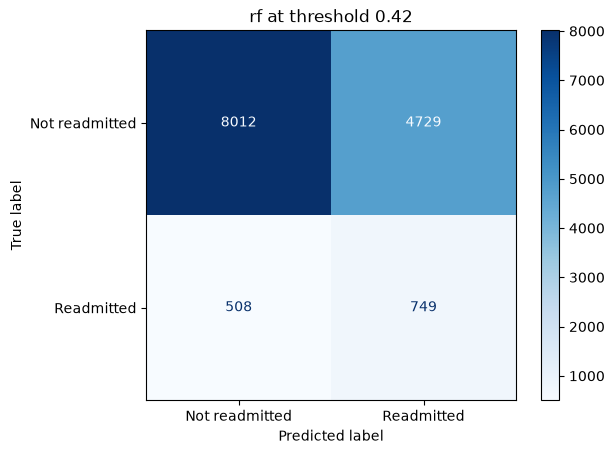

In [12]:
p_test = probas[best_name]
pred = (p_test >= threshold).astype(int)

print(f"Recall:    {recall_score(y_test, pred):.3f}")
print(f"Precision: {precision_score(y_test, pred):.3f}")
print(f"Flagged:   {pred.mean():.1%} of patients")

ConfusionMatrixDisplay(confusion_matrix(y_test, pred),
                       display_labels=["Not readmitted", "Readmitted"]).plot(cmap="Blues")
plt.title(f"{best_name} at threshold {threshold:.2f}")
plt.savefig("../reports/figures/confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

**LOGISTIC REGRESSION ODDS RATIOS**

In [13]:
lr = pipes["logreg"]
names = lr.named_steps["pre"].get_feature_names_out()
coefs = lr.named_steps["clf"].coef_[0]

odds = pd.DataFrame({"feature": names, "coef": coefs})
odds["odds_ratio"] = np.exp(odds["coef"])
odds["feature"] = odds["feature"].str.replace("num__", "").str.replace("cat__", "")

top_risk = odds.sort_values("odds_ratio", ascending=False).head(10)
top_protective = odds.sort_values("odds_ratio").head(10)

print("Highest risk:")
print(top_risk[["feature", "odds_ratio"]].round(2).to_string(index=False))
print("\nMost protective:")
print(top_protective[["feature", "odds_ratio"]].round(2).to_string(index=False))

Highest risk:
                                 feature  odds_ratio
             discharge_disposition_id_22        2.50
                  diag_2_group_Neoplasms        1.54
            medical_specialty_Nephrology        1.46
                diag_1_group_Circulatory        1.20
                  diag_3_group_Digestive        1.18
                   diag_1_group_Diabetes        1.17
                  diag_3_group_Neoplasms        1.15
                         diabetesMed_Yes        1.15
medical_specialty_Family/GeneralPractice        1.15
                        number_inpatient        1.15

Most protective:
                                     feature  odds_ratio
                  discharge_disposition_id_1        0.55
medical_specialty_Orthopedics-Reconstructive        0.66
                  discharge_disposition_id_6        0.70
                       admission_source_id_4        0.83
                        diag_3_group_Unknown        0.84
                diag_2_group_Musculoskeleta

**CHART FOR THE REPORT**

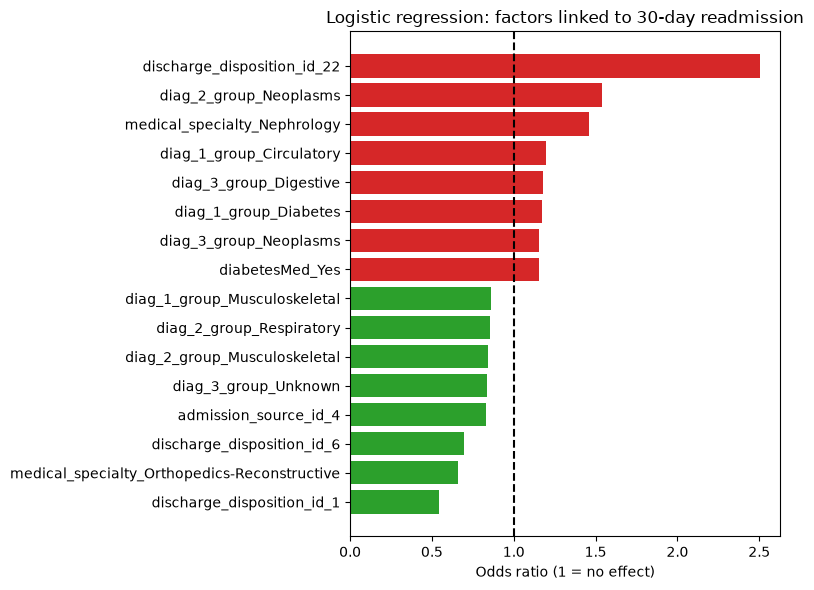

In [14]:
plot_df = pd.concat([top_risk.head(8), top_protective.head(8)]).sort_values("coef")
colors = ["tab:red" if c > 0 else "tab:green" for c in plot_df["coef"]]

plt.figure(figsize=(8, 6))
plt.barh(plot_df["feature"], plot_df["odds_ratio"], color=colors)
plt.axvline(1, color="black", linestyle="--")
plt.xlabel("Odds ratio (1 = no effect)")
plt.title("Logistic regression: factors linked to 30-day readmission")
plt.tight_layout()
plt.savefig("../reports/figures/odds_ratios.png", dpi=150, bbox_inches="tight")
plt.show()

**PERMUTATION IMPORTANCE (RANDOM FOREST)**

In [15]:
from sklearn.inspection import permutation_importance

rf = pipes["rf"]
sample = X_test.sample(5000, random_state=42)
y_sample = y_test.loc[sample.index]

result = permutation_importance(
    rf, sample, y_sample, scoring="roc_auc",
    n_repeats=5, random_state=42, n_jobs=1
)

imp = pd.DataFrame({
    "feature": X_test.columns,
    "importance": result.importances_mean,
}).sort_values("importance", ascending=False)

imp.head(10).round(4)

,feature,importance
3,discharge_disposition_id,0.0722
12,number_inpatient,0.0081
13,number_diagnoses,0.0054
21,diag_1_group,0.0054
20,had_prior_inpatient,0.0050
2,admission_type_id,0.0027
17,diabetesMed,0.0026
4,admission_source_id,0.0026
18,age_num,0.0025
7,num_lab_procedures,0.0025


**CHART**

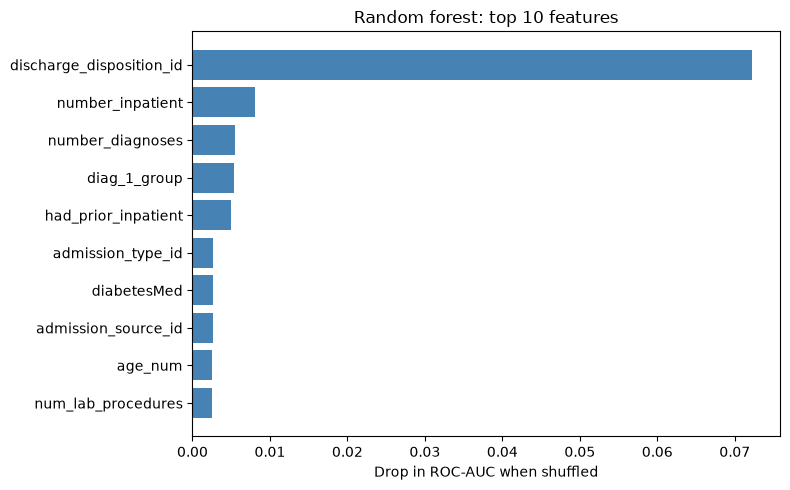

In [16]:
top = imp.head(10).sort_values("importance")
plt.figure(figsize=(8, 5))
plt.barh(top["feature"], top["importance"], color="steelblue")
plt.xlabel("Drop in ROC-AUC when shuffled")
plt.title("Random forest: top 10 features")
plt.tight_layout()
plt.savefig("../reports/figures/permutation_importance.png", dpi=150, bbox_inches="tight")
plt.show()